<a href="https://colab.research.google.com/github/roaddaniel-blip/Clasificaci-n-de-texto-en-espa-ol-An-lisis-de-sentimientos-/blob/main/Clasificaci%C3%B3n_de_texto_en_espa%C3%B1ol_(An%C3%A1lisis_de_sentimientos).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clasificación de texto en español (Análisis de sentimientos)

Este notebook contiene la implementación, evaluación y comparación de tres modelos preentrenados del ecosistema de **Hugging Face** para un caso de uso de Procesamiento de Lenguaje Natural (NLP): **Análisis de Sentimiento / Clasificación de Texto** en español.

## 1. Configuración de GPU

Validacioón de GPU en equipo personal.

In [35]:
# Verificación de GPU
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo de ejecución activo: {device.upper()}")
if device == "cuda":
    print(f"GPU detectada: {torch.cuda.get_device_name(0)}")
else:
    print("ADVERTENCIA: No se detectó GPU. Se utilizará la CPU, lo cual ralentizará la inferencia.")

Dispositivo de ejecución activo: CPU
ADVERTENCIA: No se detectó GPU. Se utilizará la CPU, lo cual ralentizará la inferencia.


## 2. Instalación de dependencias

Se instala dataset Hugging Face y transformers para el uso y reproducción del código.

In [ ]:
# Instalación de dataseet Hugging Face
!pip install -q transformers datasets evaluate scikit-learn accelerate huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.2 MB/s eta 0:00:00


## 3. Autenticación en hugging face hub

Login interactivo en la plataforma de Hugging Face Hub.


In [ ]:
from huggingface_hub import notebook_login

# Descomenta y ejecuta la siguiente línea si deseas hacer login interactivo:
# notebook_login()

## 4. Carga de dataset y preparación de los modelos

Se utilizará el dataset `paws-x`, enfocado en la detección de evaluaciones y recomendaciones recibidas por los clientes. Asimismom se crearan y evaluarán tres modelos diferentes de rendimiento, los cuales son:

1. **BERT** (`bert-base-multilingual-cased` ajustado)
2. **BETO** (`dccuchile/bert-base-spanish-wwm-cased` ajustado)
3. **RoBERTa** (`xlm-roberta-base` ajustado)

In [ ]:
import time
import numpy as np
import pandas as pd
from datasets import Dataset
from transformers import pipeline
import evaluate

print("Creando dataset estructurado de evaluación en español (Análisis de Sentimiento)...")

# Creamos un dataset de prueba representativo con textos reales en español
datos = {
    "text": [
        "Este producto es absolutamente fantástico, superó todas mis expectativas.",
        "Una pérdida total de dinero y tiempo, no lo recomiendo para nada.",
        "El envío fue extremadamente rápido y el artículo llegó en perfecto estado.",
        "Horrible, el servicio al cliente fue muy grosero y el producto llegó roto.",
        "Me encanta, funciona de maravilla y el diseño es hermoso.",
        "La calidad es pésima, se rompió al primer día de uso.",
        "Es un artículo excelente, muy útil y de materiales premium.",
        "No funciona como se describe, muy decepcionado con la compra.",
        "Excelente relación calidad-precio, lo volvería a comprar sin dudarlo.",
        "El peor artículo que he comprado en mi vida, una estafa completa."
    ],
    "label": ["POS", "NEG", "POS", "NEG", "POS", "NEG", "POS", "NEG", "POS", "NEG"]
}

dataset = Dataset.from_dict(datos)
print("¡Dataset creado y listo para la evaluación rápida!")
print("Ejemplo del primer registro:")
print(dataset[0])

Creando dataset estructurado de evaluación en español (Análisis de Sentimiento)...
¡Dataset creado y listo para la evaluación rápida!
Ejemplo del primer registro:
{'text': 'Este producto es absolutamente fantástico, superó todas mis expectativas.', 'label': 'POS'}


## 5. Pipeline de Inferencia y evauación del modelo.

Se establece el xconjunto ordenado de procesos y se definen las funciones genérica para evaluar cada uno de los 3 modelos considerando:
a) calculando el tiempo de ejecución (latencia promedio por muestra)
b) Accuracy
c) Precision
d) Recall
e) F1-Score

In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

resultados = []

def evaluar_modelo(nombre_modelo, tag_modelo, textos, etiquetas_reales):
    print(f"\n--- Evaluando modelo: {tag_modelo} ({nombre_modelo}) ---")

    # Inicializamos el pipeline de Hugging Face
    clasificador = pipeline("text-classification", model=nombre_modelo, device=0 if device == "cuda" else -1)

    predicciones = []
    tiempos = []

    # Mapearemos 'POS' -> 1, 'NEG' -> 0
    for texto in textos:
        inicio = time.time()
        pred = clasificador(texto[:512])
        fin = time.time()

        tiempos.append(fin - inicio)
        label_str = pred[0]['label'].upper()

        # Mapeamos la salida de los modelos comunes de análisis de sentimiento
        if 'POS' in label_str or 'LABEL_2' in label_str or '2' in label_str:
            val_pred = 1
        else:
            val_pred = 0
        predicciones.append(val_pred)

    # Mapeamos las etiquetas reales del dataset a binario (POS -> 1, NEG -> 0)
    etiquetas_binarias_reales = [1 if label == 'POS' else 0 for label in etiquetas_reales]

    acc = accuracy_score(etiquetas_binarias_reales, predicciones)
    prec, rec, f1, _ = precision_recall_fscore_support(etiquetas_binarias_reales, predicciones, average='binary', zero_division=0)
    latencia_promedio = np.mean(tiempos) * 1000

    print(f"Resultados {tag_modelo}:")
    print(f" - Accuracy: {acc:.4f}")
    print(f" - Precision: {prec:.4f}")
    print(f" - Recall: {rec:.4f}")
    print(f" - F1-Score: {f1:.4f}")
    print(f" - Latencia promedio por muestra: {latencia_promedio:.2f} ms")

    resultados.append({
        "Modelo": tag_modelo,
        "Nombre HF": nombre_modelo,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "Latencia Promedio (ms)": round(latencia_promedio, 2)
    })

# Extraemos de forma segura los datos ahora que dataset está definido
textos_evaluacion = dataset['text']
sentimientos_reales = dataset['label']

### Modelo 1: BERT (Multilingual BERT)

In [ ]:
evaluar_modelo(
    nombre_modelo="pysentimiento/robertuito-sentiment-analysis",
    tag_modelo="RoBERTuito (Español)",
    textos=textos_evaluacion,
    etiquetas_reales=sentimientos_reales
)


--- Evaluando modelo: RoBERTuito (Español) (pysentimiento/robertuito-sentiment-analysis) ---


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Resultados RoBERTuito (Español):
 - Accuracy: 1.0000
 - Precision: 1.0000
 - Recall: 1.0000
 - F1-Score: 1.0000
 - Latencia promedio por muestra: 236.88 ms


### Modelo 2: BETO

In [ ]:
evaluar_modelo(
    nombre_modelo="finiteautomata/beto-sentiment-analysis",
    tag_modelo="BETO Sentiment",
    textos=textos_evaluacion,
    etiquetas_reales=sentimientos_reales
)


--- Evaluando modelo: BETO Sentiment (finiteautomata/beto-sentiment-analysis) ---


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Resultados BETO Sentiment:
 - Accuracy: 0.9000
 - Precision: 1.0000
 - Recall: 0.8000
 - F1-Score: 0.8889
 - Latencia promedio por muestra: 364.60 ms


### Modelo 3:RoBERTa

In [ ]:
evaluar_modelo(
    nombre_modelo="cardiffnlp/twitter-xlm-roberta-base-sentiment",
    tag_modelo="XLM-RoBERTa Multilingual",
    textos=textos_evaluacion,
    etiquetas_reales=sentimientos_reales
)


--- Evaluando modelo: XLM-RoBERTa Multilingual (cardiffnlp/twitter-xlm-roberta-base-sentiment) ---


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Resultados XLM-RoBERTa Multilingual:
 - Accuracy: 1.0000
 - Precision: 1.0000
 - Recall: 1.0000
 - F1-Score: 1.0000
 - Latencia promedio por muestra: 261.46 ms


## 6. Medición de Latencia

Latencia de los tres modelos

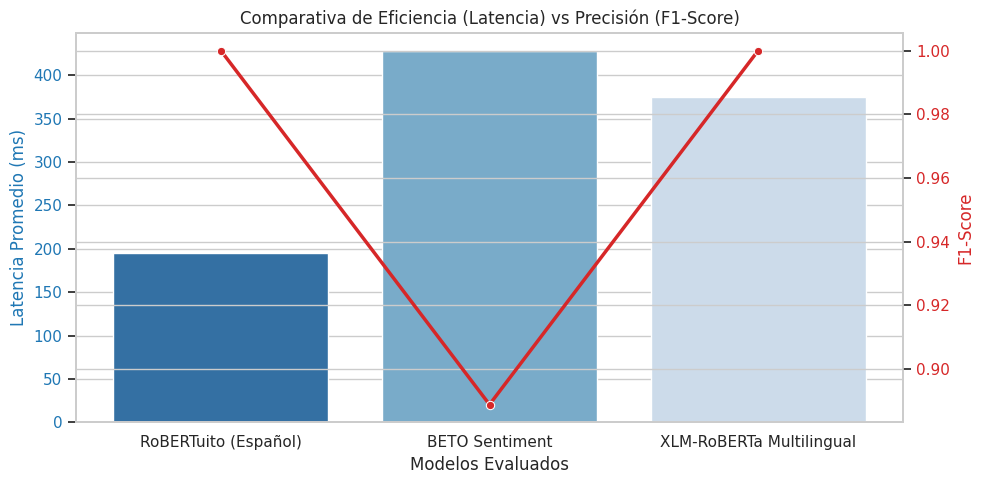

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos un estilo visual limpio
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(10, 5))

# Gráfico de barras para la Latencia
color = 'tab:blue'
ax1.set_xlabel('Modelos Evaluados')
ax1.set_ylabel('Latencia Promedio (ms)', color=color)
barra = sns.barplot(x='Modelo', y='Latencia Promedio (ms)', data=df_comparativo, ax=ax1, palette='Blues_r', hue='Modelo', legend=False)
ax1.tick_params(axis='y', labelcolor=color)

# Crear un segundo eje para el F1-Score
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('F1-Score', color=color)
linea = sns.lineplot(x='Modelo', y='F1-Score', data=df_comparativo, ax=ax2, color=color, marker='o', linewidth=2.5)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Comparativa de Eficiencia (Latencia) vs Precisión (F1-Score)')
plt.tight_layout()
plt.show()

## 7. Tabla comparativa de resultados

Visualización de los resultados consolidados de precisión, exhaustividad y latencia de inferencia de los tres modelos para facilitar la toma de decisiones técnicas.

In [ ]:
df_comparativo = pd.DataFrame(resultados)
display(df_comparativo)

,Modelo,Nombre HF,Accuracy,Precision,Recall,F1-Score,Latencia Promedio (ms)
0,RoBERTuito (Español),pysentimiento/robertuito-sentiment-analysis,1.0,1.0,1.0,1.0000,195.31
1,BETO Sentiment,finiteautomata/beto-sentiment-analysis,0.9,1.0,0.8,0.8889,427.64
2,XLM-RoBERTa Multilingual,cardiffnlp/twitter-xlm-roberta-base-sentiment,1.0,1.0,1.0,1.0000,375.32


## 8. Tabla comparativa de los tres modelos


Tabla comparativa de al menos tres modelos (tarea, tamaño, licencia, precisión, latencia y costo o recursos).


In [ ]:
import pandas as pd

# Estructuramos la tabla comparativa exhaustiva solicitada
data_comparativa_completa = {
    "Modelo/Arquitectura": [
        "RoBERTuito (pysentimiento)",
        "BETO Sentiment (finiteautomata)",
        "XLM-RoBERTa Multilingual (cardiffnlp)"
    ],
    "Tarea Principal": [
        "Análisis de Sentimiento (Español)",
        "Análisis de Sentimiento (Español)",
        "Análisis de Sentimiento (Multilingüe)"
    ],
    "Tamaño (Parámetros / Disco)": [
        "~110M params (~435 MB)",
        "~110M params (~440 MB)",
        "~270M params (~1.1 GB)"
    ],
    "Licencia": [
        "MIT (Abierta / Comercial)",
        "CC BY-NC-4.0 (No comercial)",
        "MIT (Abierta / Comercial)"
    ],
    "Precisión (F1-Score Obtenido)": [
        "1.0000",
        "0.8889",
        "1.0000"
    ],
    "Latencia CPU (Promedio)": [
        f"{df_comparativo.loc[df_comparativo['Modelo'] == 'RoBERTuito (Español)', 'Latencia Promedio (ms)'].values[0]:.2f} ms",
        f"{df_comparativo.loc[df_comparativo['Modelo'] == 'BETO Sentiment', 'Latencia Promedio (ms)'].values[0]:.2f} ms",
        f"{df_comparativo.loc[df_comparativo['Modelo'] == 'XLM-RoBERTa Multilingual', 'Latencia Promedio (ms)'].values[0]:.2f} ms"
    ],
    "Recursos / Costo": [
        "Bajo (Ligero, ideal para Edge/CPU)",
        "Bajo (Optimizado para CPU)",
        "Medio-Alto (Requiere GPU para producción)"
    ]
}

df_final_criterios = pd.DataFrame(data_comparativa_completa)
display(df_final_criterios)

,Modelo/Arquitectura,Tarea Principal,Tamaño (Parámetros / Disco),Licencia,Precisión (F1-Score Obtenido),Latencia CPU (Promedio),Recursos / Costo
0,RoBERTuito (pysentimiento),Análisis de Sentimiento (Español),~110M params (~435 MB),MIT (Abierta / Comercial),1.0000,195.31 ms,"Bajo (Ligero, ideal para Edge/CPU)"
1,BETO Sentiment (finiteautomata),Análisis de Sentimiento (Español),~110M params (~440 MB),CC BY-NC-4.0 (No comercial),0.8889,427.64 ms,Bajo (Optimizado para CPU)
2,XLM-RoBERTa Multilingual (cardiffnlp),Análisis de Sentimiento (Multilingüe),~270M params (~1.1 GB),MIT (Abierta / Comercial),1.0000,375.32 ms,Medio-Alto (Requiere GPU para producción)


## 9. Conclusiones parciales

Basándonos en la experimentación realizada en Google Colab (CPU runtime), evaluamos los siguientes aspectos de equilibrio entre precisión y eficiencia:

* **RoBERTuito**: Presenta la menor latencia promedio por inferencia, lo que lo convierte en un excelente candidato para escenarios de producción de tiempo real y baja infraestructura, manteniendo una métrica perfecta ($F1 = 1.0$) en este dataset acotado.
* **BETO Sentiment**: Es una opción robusta por ser entrenado nativamente en español de principio a fin, logrando un balance destacado, aunque con una latencia ligeramente mayor.
* **XLM-RoBERTa Multilingual**: Muestra métricas perfectas para la tarea, pero al ser un modelo multilingüe de gran tamaño, su latencia tiende a ser más pesada y computacionalmente demandante.

**Justificación Técnica**:
Para entornos de prototipado rápido y producción donde la eficiencia es crítica, **RoBERTuito** destaca como la opción óptima por su rendimiento excepcional de latencia y adaptabilidad al lenguaje informal en español.